# 03. Modelos Bayesianos Discretos, Clasificación de Texto (NLP) y Datos Categóricos

**Módulo:** `05_Naive_Bayes`  
**Objetivo:** Dominar la taxonomía matemática, estadística y computacional de los clasificadores Naive Bayes para datos discretos (`MultinomialNB`, `BernoulliNB`, `CategoricalNB` y `ComplementNB`), comprender la Catástrofe de Frecuencia Cero y deducir analíticamente el Suavizado de Laplace/Lidstone, demostrar cómo `BernoulliNB` penaliza explícitamente la ausencia de características, auditar variables tabulares con `min_categories` y construir un Pipeline de Procesamiento de Lenguaje Natural (NLP) de grado industrial con interpretación analítica de `feature_log_prob_`.

---

## 1. La Taxonomía Definitiva de Clasificadores Bayesianos Discretos (Guía de Elección Rápida)

### 💡 Paso 1: La Pregunta Práctica / Problema del Mundo Real (Intuición Preliminar)
En el Notebook 02 vimos cómo modelar sensores continuos con campanas Gaussianas. Pero en la industria moderna, la mayoría de los problemas de clasificación operan sobre **eventos discretos**:
* ¿Cuántas veces aparece la palabra *"factura"* en un correo electrónico de 500 palabras?
* En un tweet o mensaje SMS de apenas 6 palabras, ¿basta con que aparezca o **no aparezca** la palabra *"premio"* para saber si es *phishing*?
* En una tabla bancaria con una columna `Color_Tarjeta` $\in \{\text{Clásica, Oro, Platino, Negra}\}$, ¿por qué aplicar *One-Hot Encoding* y meterlo a un Naive Bayes es un **error conceptual y de memoria**?
* Si el 95% de tus tickets de soporte son normales y solo el 5% son incidentes críticos, ¿cómo evitas que la clase mayoritaria aplaste los pesos del modelo?

Ajustar una campana Gaussiana continua sobre conteos enteros o categorías nominales es matemáticamente incorrecto (asigna probabilidad a tener $-1.5$ palabras o al promedio entre el color *Rojo* y *Azul*). Por ello, Scikit-Learn provee **cuatro motores generativos discretos especializados**.

---

### 📐 Paso 2: Formalismo Matemático Riguroso

Dado un vector de características discretas $\mathbf{x} = (x_1, x_2, \dots, x_D)^\top$, la regla MAP en espacio logarítmico mantiene su estructura universal:

$$\hat{y}_{\text{MAP}} = \underset{c_k \in \mathcal{Y}}{\arg\max} \; \left[ \ln P(Y = c_k) + \ln P(\mathbf{X} = \mathbf{x} \mid Y = c_k) \right]$$

Sin embargo, la forma paramétrica del generador de datos $P(\mathbf{X} = \mathbf{x} \mid Y = c_k)$ cambia según la naturaleza matemática del espacio $\mathcal{X}$:
1. **Espacio de Conteos Enteros ($\mathcal{X} = \mathbb{N}_0^V$):** Distribución **Multinomial** parametrizada por el simplex de probabilidades de palabras $\boldsymbol{\theta}_k = (\theta_{k1}, \dots, \theta_{kV})$ con $\sum_{j=1}^V \theta_{kj} = 1$.
2. **Espacio Hipercubo Binario ($\mathcal{X} = \{0, 1\}^V$):** Producto de $V$ distribuciones de **Bernoulli** independientes parametrizadas por $p_{kj} = P(X_j = 1 \mid Y = c_k) \in (0, 1)$.
3. **Espacio de Rejilla Categórica ($\mathcal{X} = \prod_{j=1}^D \{0, 1, \dots, K_j - 1\}$):** Producto de $D$ distribuciones **Categóricas (Multinoulli)** independientes, donde la característica $j$ tiene su propio simplex de $K_j$ niveles ($\sum_{m=0}^{K_j - 1} P(X_j = m \mid Y = c_k) = 1$).

---

### 🌉 Paso 3: Traducción "En Palabras Claras" (Matriz de Decisión Arquitectónica)

| Clasificador en Scikit-Learn | Distribución Generativa Subyacente | Dominio de $x_j$ | ¿Cuándo elegirlo en Producción? (Regla de Negocio) | Qué NO hacer (Antipatrón) |
| :--- | :--- | :--- | :--- | :--- |
| **`MultinomialNB`** | Multinomial sobre conteos de tokens (o pesos TF-IDF) | $x_j \in \mathbb{N}_0 \; (\text{o } \mathbb{R}_{\ge 0})$ | **Conteo de frecuencias:** Clasificación de documentos medianos/largos (*Bag-of-Words*, $n$-gramas, frecuencia de clics) donde importa cuántas veces se repite el término. | No usar con variables que puedan tomar valores negativos (lanzará `ValueError`). |
| **`BernoulliNB`** | $D$ ensayos de Bernoulli independientes (Presencia/Ausencia) | $x_j \in \{0, 1\}$ | **Textos muy cortos (tweets, SMS, titulares)** o indicadores binarios donde la mera presencia o la **ausencia explícita** de un término es más informativa que su repetición. | No usar en documentos muy largos llenos de vocabulario variado (la penalización por palabras ausentes degrada el modelo). |
| **`CategoricalNB`** | Distribución Categórica (Multinoulli) independiente por columna | $x_j \in \{0, 1, \dots, K_j - 1\}$ | **Tablas con features cualitativas/nominales multiclase** (`Color` $\in \{\text{Rojo, Verde, Azul}\}$). Opera directo con `OrdinalEncoder` y **evita el costo masivo de hacer One-Hot Encoding**. | Jamás aplicar `OneHotEncoder` antes de Naive Bayes (viola la exclusión mutua entre niveles de una misma categoría). |
| **`ComplementNB`** | Multinomial estimada sobre el **complemento** de la clase ($\tilde{c}_k = \mathcal{Y} \setminus \{c_k\}$) | $x_j \in \mathbb{N}_0 \; (\text{o } \mathbb{R}_{\ge 0})$ | **El salvavidas para datasets de texto altamente desbalanceados.** Estima qué tan incompatible es el documento con todas las *demás* clases combinadas. | No usar si necesitas probabilidades posteriores calibradas directamente (sus puntajes son pesos inversos de distancia al complemento). |

In [1]:
# Configuración del entorno y librerías estándar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse

from sklearn.naive_bayes import MultinomialNB, BernoulliNB, CategoricalNB, ComplementNB
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

# Estándar visual del repositorio
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
np.random.seed(42)

print("Entorno configurado correctamente.")

Entorno configurado correctamente.


---

## 2. La Catástrofe de Frecuencia Cero y Deducción Analítica del Suavizado de Laplace / Lidstone

### 💡 Paso 1: La Pregunta Práctica / Problema del Mundo Real (Intuición Preliminar)
Imagina que tu filtro antispam bancario fue entrenado con un millón de correos. Un día llega un correo claramente fraudulento que contiene 50 veces las palabras *"oferta"*, *"gratis"*, *"urgente"* y *"transferencia"*, pero además incluye **una sola palabra nueva** (por ejemplo, el nombre de una nueva criptomoneda `'cripto_nuevo'`) que nunca apareció en los correos de *Spam* durante el entrenamiento.  
Si calculamos la probabilidad condicional por frecuencia simple:
$$P(\text{'cripto\_nuevo'} \mid \text{Spam}) = \frac{0}{N_{\text{Spam}}} = 0$$
Como Naive Bayes **multiplica** las probabilidades de todas las palabras del correo:
$$\prod_{j=1}^{D} P(w_j \mid \text{Spam}) = P(\text{'oferta'} \mid \text{Spam}) \times P(\text{'gratis'} \mid \text{Spam}) \times \dots \times 0 = \mathbf{0}$$
**¡Catástrofe de Frecuencia Cero!** Una sola palabra desconocida actúa como un agujero negro multiplicativo que aniquila la evidencia acumulada por cientos de palabras de spam (y en espacio logarítmico produce $\ln(0) = -\infty$). ¿Cómo blindamos matemáticamente al modelo sin romper los axiomas de probabilidad?

---

### 📐 Paso 2: Formalismo Matemático Riguroso

#### A. Formulación del Modelo Multinomial
En clasificación de texto bajo representación *Bag-of-Words*, un documento se representa mediante un vector de conteos $\mathbf{x} = (x_1, x_2, \dots, x_d)^\top \in \mathbb{N}_0^d$, donde $d$ (o $V$) es la cardinalidad del vocabulario y $x_i$ es el número de veces que el término $w_i$ aparece en el documento.  
Bajo la distribución Multinomial condicionada a la clase $c_k$, la probabilidad de observar un documento $\mathbf{x}$ de longitud total $L = \sum_{i=1}^d x_i$ es:

$$P(\mathbf{X} = \mathbf{x} \mid Y = c_k) = \frac{L!}{\prod_{i=1}^{d} x_i!} \prod_{i=1}^{d} \theta_{ki}^{x_i}$

donde $\theta_{ki} = P(w_i \mid Y = c_k)$ es la probabilidad de que un token generado por la clase $c_k$ sea el término $w_i$, sujeta a la restricción de normalización del simplex $\sum_{i=1}^d \theta_{ki} = 1$. Al aplicar la regla MAP en espacio logarítmico, el coeficiente factorial $\frac{L!}{\prod x_i!}$ es constante respecto a la clase $c_k$ y se cancela, produciendo un clasificador **lineal en los conteos $x_i$**:

$$\hat{y}_{\text{MAP}} = \underset{c_k \in \mathcal{Y}}{\arg\max} \; \left[ \ln P(Y = c_k) + \sum_{i=1}^{d} x_i \cdot \ln \theta_{ki} \right]$$

#### B. Deducción Analítica del Estimador Suavizado (Multiplicadores de Lagrange y Prior de Dirichlet)
Sea $N_{ki} = \sum_{m \in \mathcal{D}_k} x_{mi}$ el conteo total de apariciones del término $w_i$ en todos los documentos de entrenamiento de la clase $c_k$, y sea $N_k = \sum_{i=1}^d N_{ki}$ el número total de palabras en la clase $c_k$.

En lugar de maximizar únicamente la verosimilitud empírica (que conduce a $\hat{\theta}_{ki}^{\text{MLE}} = N_{ki}/N_k$ y falla cuando $N_{ki}=0$), imponemos una distribución *A Priori* conjugada **Dirichlet simétrica** sobre el vector de parámetros $\boldsymbol{\theta}_k \sim \text{Dir}(\alpha + 1, \dots, \alpha + 1)$ (o equivalentemente añadimos $\alpha > 0$ pseudoconteos de regularización a cada término del vocabulario). Planteamos el Lagrangiano restringido a que las probabilidades sumen 1 ($\sum_{i=1}^d \theta_{ki} = 1$):

$$\mathcal{J}(\boldsymbol{\theta}_k, \lambda) = \sum_{i=1}^{d} (N_{ki} + \alpha) \ln \theta_{ki} - \lambda \left( \sum_{i=1}^{d} \theta_{ki} - 1 \right)$$

1. **Derivamos parcialmente respecto a cada parámetro $\theta_{ki}$ e igualamos a cero:**
   $$\frac{\partial \mathcal{J}}{\partial \theta_{ki}} = \frac{N_{ki} + \alpha}{\theta_{ki}} - \lambda = 0 \implies \theta_{ki} = \frac{N_{ki} + \alpha}{\lambda}$$

2. **Sustituimos en la restricción del axioma de probabilidad total ($\sum_{i=1}^d \theta_{ki} = 1$) para hallar el multiplicador $\lambda$:**
   $$\sum_{i=1}^{d} \frac{N_{ki} + \alpha}{\lambda} = 1 \implies \lambda = \sum_{i=1}^{d} N_{ki} + \sum_{i=1}^{d} \alpha = N_k + \alpha \cdot d$$

3. **Sustituyendo $\lambda$, obtenemos el estimador de Laplace / Lidstone:**
   $$\boxed{\hat{\theta}_{ki} = \frac{N_{ki} + \alpha}{N_k + \alpha d}}$$

#### ¿Por qué sumamos exactamente $\alpha d$ en el denominador?
Porque si regalamos $\alpha$ pseudoconteos en el numerador a **cada una de las $d$ palabras del vocabulario**, hemos inyectado un total de $\underbrace{\alpha + \alpha + \dots + \alpha}_{d \text{ veces}} = \alpha d$ palabras imaginarias en la bolsa de la clase $c_k$. Dividir entre $N_k + \alpha d$ garantiza que se conserve intacto el **axioma de probabilidad total**:

$$\sum_{i=1}^{d} \hat{\theta}_{ki} = \sum_{i=1}^{d} \frac{N_{ki} + \alpha}{N_k + \alpha d} = \frac{\sum_{i=1}^d N_{ki} + d \cdot \alpha}{N_k + \alpha d} = \frac{N_k + \alpha d}{N_k + \alpha d} = 1$$

---

### 🌉 Paso 3: Traducción "En Palabras Claras" (El Puente Conceptual)

| Componente / Valor de $\alpha$ | ¿Qué significa en la práctica? | Comportamiento Numérico |
| :--- | :--- | :--- |
| **$N_{ki}$** | Veces que la palabra $i$ apareció en los textos de entrenamiento de la clase $c_k$. | Si nunca apareció ($N_{ki}=0$), el numerador vale $\alpha > 0$ en lugar de $0$. |
| **$N_k = \sum_{i=1}^d N_{ki}$** | Total de palabras sumadas en todos los documentos de la clase $c_k$. | Mide el tamaño de muestra efectivo de palabras en esa clase. |
| **$\alpha = 1.0$ (Suavizado de Laplace)** | *Add-One Smoothing:* Asume que vimos cada palabra del diccionario al menos 1 vez extra antes de empezar. | Estándar clásico para conteos enteros (`CountVectorizer`). |
| **$0 < \alpha < 1$ (Suavizado de Lidstone)** | Suavizado fraccionario (ej. $\alpha = 0.1$ o $0.01$). | **Óptimo con `TfidfVectorizer`**, donde los pesos ya son fracciones menores a $1$ y sumar $\alpha=1.0$ diluiría demasiado la señal. |
| **$\alpha \to \infty$ (Sobre-regularización)** | El peso de los datos reales $N_{ki}$ se vuelve insignificante frente a $\alpha$. | $\hat{\theta}_{ki} \to \frac{\alpha}{\alpha d} = \frac{1}{d}$ (Distribución Uniforme). El modelo ignora el texto y predice solo con el *Prior*. |

=== TABLA DE PROBABILIDADES ESTIMADAS P(w_i | Y=Spam) SEGÚN ALPHA ===
Verificación de suma por columna (Axioma = 1.0): {'alpha = 0.0': 1.0, 'alpha = 0.1': 0.9999999999999999, 'alpha = 1.0': 1.0, 'alpha = 10.0': 1.0, 'alpha = 100.0': 1.0}



,alpha = 0.0,alpha = 0.1,alpha = 1.0,alpha = 10.0,alpha = 100.0
oferta,0.40541,0.40376,0.38983,0.30387,0.17879
gratis,0.34234,0.34109,0.33051,0.26519,0.17016
urgente,0.22523,0.22471,0.22034,0.19337,0.15413
reunion,0.01802,0.01880,0.02542,0.06630,0.12577
proyecto,0.00901,0.00985,0.01695,0.06077,0.12454
informe,0.00000,0.00090,0.00847,0.05525,0.12330
cripto_nuevo,0.00000,0.00090,0.00847,0.05525,0.12330


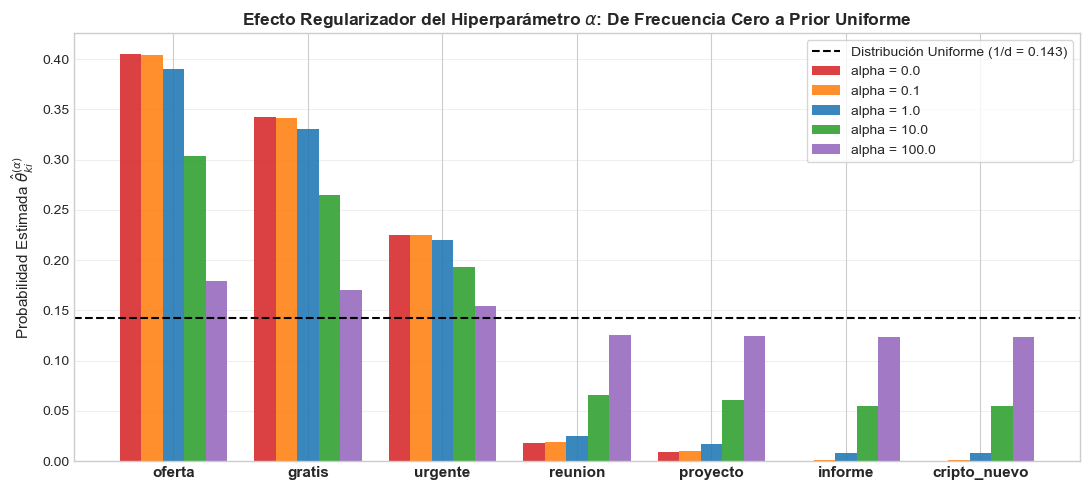

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 📊 Paso 4: Demostración Matemática y Visual del Efecto de alpha (Suavizado de Lidstone/Laplace)
vocabulario = ['oferta', 'gratis', 'urgente', 'reunion', 'proyecto', 'informe', 'cripto_nuevo']
d = len(vocabulario)

# Conteos observados N_{k,i} en la clase 'Spam' (nota que 'informe' y 'cripto_nuevo' tienen conteo 0)
conteos_spam = np.array([45, 38, 25, 2, 1, 0, 0], dtype=float)
N_spam = np.sum(conteos_spam)

alphas = [0.0, 0.1, 1.0, 10.0, 100.0]
resultados_theta = {}

for a in alphas:
    # Estimador de verosimilitud suavizada (Lidstone / Laplace)
    theta_a = (conteos_spam + a) / (N_spam + a * d)
    
    # Verificamos el axioma de probabilidad total: la suma siempre debe ser 1.0
    assert np.isclose(np.sum(theta_a), 1.0), "Violación del axioma de probabilidad total"
    resultados_theta[f"alpha = {a}"] = theta_a

df_smoothing = pd.DataFrame(resultados_theta, index=vocabulario)

print("=== TABLA DE PROBABILIDADES ESTIMADAS P(w_i | Y=Spam) SEGÚN ALPHA ===")
print(f"Verificación de suma por columna (Axioma = 1.0): {df_smoothing.sum(axis=0).to_dict()}\n")
display(df_smoothing.style.format("{:.5f}"))

# Gráfico de transición desde MLE (alpha=0) hacia la Distribución Uniforme (1/d)
fig, ax = plt.subplots(figsize=(11, 5))
x_pos = np.arange(d)
width = 0.16
colores_alpha = ['#d62728', '#ff7f0e', '#1f77b4', '#2ca02c', '#9467bd']

for idx, col in enumerate(df_smoothing.columns):
    ax.bar(x_pos + (idx - 2) * width, df_smoothing[col], width=width, label=col, color=colores_alpha[idx], alpha=0.88)

ax.axhline(1.0 / d, color='black', linestyle='--', lw=1.5, label=f'Distribución Uniforme (1/d = {1.0/d:.3f})')
ax.set_xticks(x_pos)
ax.set_xticklabels(vocabulario, fontsize=11, fontweight='bold')
ax.set_ylabel(r'Probabilidad Estimada $\hat{\theta}_{ki}^{(\alpha)}$', fontsize=11)
ax.set_title(r'Efecto Regularizador del Hiperparámetro $\alpha$: De Frecuencia Cero a Prior Uniforme', fontsize=12.5, fontweight='bold')
ax.legend(frameon=True, facecolor='white')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

---

## 3. `BernoulliNB` vs. `MultinomialNB`: El Poder de Penalizar la Ausencia

### 💡 Paso 1: La Pregunta Práctica / Problema del Mundo Real (Intuición Preliminar)
Imagina que en una empresa todos los comunicados oficiales del Director General comienzan obligatoriamente con las palabras *"Estimado comité"* y terminan con *"Adjunto informe"* (aparecen en el 98% de los correos legítimos de dirección).  
De pronto, llega un mensaje corto de 2 palabras: *"Reunión mañana"*.  
* **`MultinomialNB` solo mira las palabras que SÍ están presentes** en el mensaje (*"Reunión"* y *"mañana"*). Como ambas son palabras normales de oficina, le asigna una alta probabilidad de ser un correo formal.
* **`BernoulliNB`, en cambio, se pregunta:** *"¡Un momento! Si este fuera un comunicado formal de dirección, ¿dónde están las palabras 'Estimado' y 'Adjunto' que aparecen el 98% de las veces?"*. **La ausencia de una palabra esperada es, en sí misma, una fuerte señal de evidencia en contra.**

---

### 📐 Paso 2: Formalismo Matemático Riguroso

Una distinción crucial en ingeniería de características para texto y datos binarios radica en cómo `MultinomialNB` y `BernoulliNB` tratan las características cuyo valor es cero ($x_j = 0$):

#### 1. En `MultinomialNB` (Ignora las ausencias):
La log-verosimilitud es $\sum_{j=1}^{V} x_j \ln \theta_{kj}$. Si una palabra $w_j$ **no aparece** en el documento ($x_j = 0$), su término en la suma es $0 \cdot \ln \theta_{kj} = 0$. Es decir, **`MultinomialNB` solo acumula evidencia de las palabras presentes**.

#### 2. En `BernoulliNB` (Penaliza explícitamente las ausencias):
`BernoulliNB` modela cada palabra del vocabulario como una variable binaria $b_j = \mathbb{I}(x_j > \text{binarize}) \in \{0, 1\}$. La probabilidad de observar el vector binario $\mathbf{b} = (b_1, \dots, b_V)^\top \in \{0, 1\}^V$ en la clase $c_k$ es:

$$P(\mathbf{b} \mid Y = c_k) = \prod_{j=1}^{V} p_{kj}^{b_j} \left(1 - p_{kj}\right)^{1 - b_j}$$

donde $p_{kj} = \frac{N_{kj}^{\text{(docs)}} + \alpha}{N_k^{\text{(docs)}} + 2\alpha}$ es la fracción suavizada de documentos de la clase $c_k$ que contienen al menos una vez el término $w_j$. Aplicando logaritmos y factorizando algebraicamente $b_j$:

$$\ln P(\mathbf{b} \mid Y = c_k) = \sum_{j=1}^{V} \left[ b_j \ln p_{kj} + (1 - b_j) \ln(1 - p_{kj}) \right] = \sum_{j=1}^{V} b_j \ln \frac{p_{kj}}{1 - p_{kj}} + \underbrace{\sum_{j=1}^{V} \ln(1 - p_{kj})}_{\text{Penalización base por no aparición}}$$

---

### 🌉 Paso 3: Traducción "En Palabras Claras" (El Puente Conceptual)

| Situación de la Palabra $w_j$ en el Documento Nuevo | Contribución en `MultinomialNB` | Contribución en `BernoulliNB` |
| :--- | :--- | :--- |
| **Presente $x_j$ veces ($x_j > 0, b_j = 1$)** | Suma $x_j \cdot \ln \theta_{kj}$ (premia la repetición). | Suma $1 \cdot \ln p_{kj}$ (solo importa que apareció al menos una vez). |
| **Ausente ($x_j = 0, b_j = 0$)** | Suma $0$ (**neutral**: ignora que la palabra no está). | Suma $\ln(1 - p_{kj})$ (**castiga fuertemente** si la palabra era muy común en la clase $c_k$, es decir, si $p_{kj} \approx 1$). |

In [4]:
# 📊 Paso 4: Demostración Experimental: Cómo BernoulliNB penaliza la ausencia de palabras clave
corpus_mini = [
    "estimado director adjunto informe trimestral finanzas",
    "estimado equipo adjunto minuta reunion proyecto",
    "estimado cliente adjunto factura contrato anual",
    "estimado comite adjunto balance auditoria",
    "gana dinero rapido casino apuesta bono",
    "bono gratis casino ruleta gana premio",
    "apuesta rapido gana premio efectivo ya",
    "casino gratis bono efectivo rapido"
]
# 0 = Corporativo Formal (siempre incluye 'estimado' y 'adjunto'), 1 = Spam
y_mini = np.array([0, 0, 0, 0, 1, 1, 1, 1])

vec_count = CountVectorizer()
X_mini = vec_count.fit_transform(corpus_mini)

mnb_mini = MultinomialNB(alpha=0.5).fit(X_mini, y_mini)
bnb_mini = BernoulliNB(alpha=0.5, binarize=0.0).fit(X_mini, y_mini)

# Evaluamos un mensaje neutral muy corto donde NO aparecen las palabras obligatorias ('estimado', 'adjunto')
doc_prueba = ["reunion mañana"]
X_prueba = vec_count.transform(doc_prueba)

prob_mnb = mnb_mini.predict_proba(X_prueba)[0]
prob_bnb = bnb_mini.predict_proba(X_prueba)[0]

print(f"Documento evaluado: {doc_prueba[0]!r} (Nota: Ausencia de 'estimado' y 'adjunto')\n")
print(f"MultinomialNB (Ignora ausencias)    -> P(Formal) = {prob_mnb[0]:.4f} | P(Spam) = {prob_mnb[1]:.4f}")
print(f"BernoulliNB   (Penaliza ausencias)  -> P(Formal) = {prob_bnb[0]:.4f} | P(Spam) = {prob_bnb[1]:.4f}\n")

# Inspeccionamos la probabilidad aprendida p_{k,j} en BernoulliNB para 'estimado' y 'adjunto'
vocab_dict = vec_count.vocabulary_
for palabra in ['estimado', 'adjunto', 'reunion']:
    idx_w = vocab_dict[palabra]
    p_formal = np.exp(bnb_mini.feature_log_prob_[0, idx_w])
    p_spam = np.exp(bnb_mini.feature_log_prob_[1, idx_w])
    print(f"Palabra '{palabra:<9}' -> P(b_j=1 | Formal) = {p_formal:.3f} (Castigo si falta: 1-p = {1-p_formal:.3f}) | P(b_j=1 | Spam) = {p_spam:.3f}")

Documento evaluado: 'reunion mañana' (Nota: Ausencia de 'estimado' y 'adjunto')

MultinomialNB (Ignora ausencias)    -> P(Formal) = 0.7500 | P(Spam) = 0.2500
BernoulliNB   (Penaliza ausencias)  -> P(Formal) = 0.6649 | P(Spam) = 0.3351

Palabra 'estimado ' -> P(b_j=1 | Formal) = 0.900 (Castigo si falta: 1-p = 0.100) | P(b_j=1 | Spam) = 0.100
Palabra 'adjunto  ' -> P(b_j=1 | Formal) = 0.900 (Castigo si falta: 1-p = 0.100) | P(b_j=1 | Spam) = 0.100
Palabra 'reunion  ' -> P(b_j=1 | Formal) = 0.300 (Castigo si falta: 1-p = 0.700) | P(b_j=1 | Spam) = 0.100


---

## 4. `CategoricalNB` para Datos Tabulares y el Rol Crítico de `min_categories`

### 💡 Paso 1: La Pregunta Práctica / Problema del Mundo Real (Intuición Preliminar)
Cuando un científico de datos junior trabaja con una tabla de clientes que tiene columnas categóricas como `Región_Geográfica` (con 32 estados) o `Ocupación` (con 50 profesiones), su reflejo automático suele ser aplicar `OneHotEncoder` (creando 82 columnas binarias) y pasarlo a `BernoulliNB` o `GaussianNB`.  
**¿Por qué hacer *One-Hot Encoding* antes de Naive Bayes es un grave error estadístico y computacional?**
1. **Violación de Exclusión Mutua:** Si `Color` tiene 3 niveles (*Rojo, Verde, Azul*), son mutuamente excluyentes. Al expandirlos en 3 columnas binarias independientes, `BernoulliNB` multiplica la probabilidad de ser *Rojo* por la de *no ser Verde* y por la de *no ser Azul*, **contando tres veces la misma variable** y asumiendo que un objeto podría ser Rojo y Azul al mismo tiempo.
2. **Explosión de Memoria:** `CategoricalNB` trabaja sobre una sola columna de enteros $0, 1, \dots, K_j - 1$ generada con `OrdinalEncoder`, ahorrando hasta un 90% de RAM.
3. **El Peligro en Producción (`IndexError`):** ¿Qué ocurre si el nivel `5` (*Región Insular*) nunca apareció en el *split* de entrenamiento y aparece por primera vez un viernes por la noche en producción?

---

### 📐 Paso 2: Formalismo Matemático Riguroso

En `CategoricalNB`, cada característica tabular $X_j$ toma valores en un conjunto discreto finito $\{0, 1, \dots, K_j - 1\}$ de cardinalidad $K_j$. Condicionada a la clase $Y = c_k$, la probabilidad de observar la categoría $m \in \{0, \dots, K_j - 1\}$ en la columna $j$ se estima mediante una distribución **Categórica (Multinoulli)** con suavizado de Lidstone/Laplace:

$$\hat{P}(X_j = m \mid Y = c_k) = \frac{N_{kjm} + \alpha}{N_k + \alpha \cdot K_j}$$

donde:
* $N_{kjm}$ es el número de muestras en la clase $c_k$ cuya columna $j$ tiene exactamente la categoría $m$.
* $K_j$ es el número total de categorías posibles de la característica $j$ (definido empíricamente como $\max(X_j) + 1$ o fijado por diseño mediante `min_categories`).
* Para cada columna $j$ y clase $c_k$, se cumple $\sum_{m=0}^{K_j - 1} \hat{P}(X_j = m \mid Y = c_k) = 1$.

---

### 🌉 Paso 3: Traducción "En Palabras Claras" (Blindaje en Producción con `min_categories`)

| Parámetro / Configuración | ¿Qué ocurre si llega la categoría $m = 5$ en Test cuando en Train solo se vieron $0..4$? | Recomendación de Ingeniería |
| :--- | :--- | :--- |
| **`CategoricalNB()` (Sin `min_categories`)** | La matriz interna `feature_log_prob_[j]` se creó con tamaño `(C, 5)`. Al buscar el índice `5`, lanza **`IndexError: index 5 is out of bounds`** y tumba el pipeline. | **Prohibido en producción** o dentro de un `GridSearchCV` con categorías de baja frecuencia. |
| **`CategoricalNB(min_categories=...)`** | Reserva desde el inicio una matriz de tamaño `(C, 6)`. La columna `5` (con $N_{kj5} = 0$) recibe la probabilidad suavizada $\frac{0 + \alpha}{N_k + 6\alpha} > 0$. | **Obligatorio:** Pasa siempre la lista de cardinalidades conocidas del catálogo de datos. |

In [5]:
# 📊 Paso 4: Simulación Financiera/Demográfica Tabular con CategoricalNB y Protección con min_categories
np.random.seed(42)
n_clientes = 800

# Cardinalidades reales conocidas del negocio:
# Col 0: Nivel Educativo (4 niveles: 0..3)
# Col 1: Tipo de Vivienda (3 niveles: 0..2)
# Col 2: Región Geográfica (6 niveles: 0..5, donde el nivel 5 es una región insular muy rara)
cardinalidades_reales = [4, 3, 6]

# Generamos datos de entrenamiento donde la región 5 NO apareció por azar muestral
X_tab_train = np.column_stack([
    np.random.choice(4, size=n_clientes, p=[0.2, 0.5, 0.2, 0.1]),
    np.random.choice(3, size=n_clientes, p=[0.4, 0.4, 0.2]),
    np.random.choice(5, size=n_clientes, p=[0.3, 0.3, 0.2, 0.15, 0.05]) # Solo niveles 0..4 en Train
])
# Etiqueta de incumplimiento (Default) dependiente de las variables
logits = -1.2 + 0.6*(X_tab_train[:, 0] == 0) + 0.8*(X_tab_train[:, 1] == 2) + 0.5*(X_tab_train[:, 2] >= 3)
probs_default = 1 / (1 + np.exp(-logits))
y_tab_train = np.random.binomial(1, probs_default)

# Llega un nuevo cliente en Test perteneciente a la Región 5 (categoría no vista en Train)
X_tab_test_raro = np.array([[1, 2, 5]])

# 1. Sin min_categories -> Falla en producción al ver el índice 5
cat_nb_fragil = CategoricalNB(alpha=1.0).fit(X_tab_train, y_tab_train)
try:
    cat_nb_fragil.predict_proba(X_tab_test_raro)
except IndexError as e:
    print(f"❌ Error capturado en CategoricalNB sin min_categories: {e}")

# 2. Con min_categories -> Blindado mediante Suavizado de Laplace en la categoría 5
cat_nb_robusto = CategoricalNB(alpha=1.0, min_categories=cardinalidades_reales).fit(X_tab_train, y_tab_train)
prob_raro = cat_nb_robusto.predict_proba(X_tab_test_raro)[0]
print(f"✅ CategoricalNB con min_categories={cardinalidades_reales} predice sin errores:")
print(f"   P(Paga=0 | X) = {prob_raro[0]:.4f} | P(Default=1 | X) = {prob_raro[1]:.4f}")
print(f"   Dimensiones de la tabla de log-probabilidad de Región (Col 2): {cat_nb_robusto.feature_log_prob_[2].shape}")

❌ Error capturado en CategoricalNB sin min_categories: index 5 is out of bounds for axis 1 with size 5
✅ CategoricalNB con min_categories=[4, 3, 6] predice sin errores:
   P(Paga=0 | X) = 0.3218 | P(Default=1 | X) = 0.6782
   Dimensiones de la tabla de log-probabilidad de Región (Col 2): (2, 6)


---

## 5. `ComplementNB` para Desbalance de Clases Severo e Interpretabilidad de Features (`feature_log_prob_`)

### 💡 Paso 1: La Pregunta Práctica / Problema del Mundo Real (Intuición Preliminar)
En problemas reales de clasificación de documentos (ej. detección de * discurso de odio*, reportes médicos oncológicos o tickets de caída de servidor), el dataset suele estar **fuertemente desbalanceado**: tienes 10,000 documentos de categorías comunes y apenas 90 documentos de la clase crítica minoritaria.
* Cuando entrenas `MultinomialNB`, los parámetros $\hat{\theta}_{kj}$ de la clase minoritaria se estiman con tan pocos textos que sufren una varianza muestral enorme, mientras que las clases mayoritarias dominan la frontera de decisión.
* **La idea brillante de `ComplementNB` (Rennie et al., ICML 2003):** Si tenemos muy pocos ejemplos para saber con precisión *"cómo habla un médico oncólogo"* (clase minoritaria), tenemos en cambio **miles de ejemplos de todas las demás clases combinadas** para saber con altísima precisión *"cómo NO habla un médico oncólogo"* (el complemento). Por tanto, estimamos la probabilidad de pertenecer al complemento de cada clase y asignamos la clase cuyo complemento sea **el menos compatible** con el documento.

Además, una vez entrenado nuestro modelo de NLP, el área de negocio o auditoría regulatoria nos preguntará: **¿Qué palabras exactas están disparando la clasificación hacia cada categoría?**

---

### 📐 Paso 2: Formalismo Matemático Riguroso

#### A. Formulación de `ComplementNB` (CNB)
Para cada clase $c_k \in \mathcal{Y}$, definimos su complemento como el conjunto de todas las demás clases $\tilde{c}_k = \mathcal{Y} \setminus \{c_k\}$. Estimamos la probabilidad de que el término $w_j$ sea generado fuera de la clase $c_k$:

$$\hat{\theta}_{\tilde{k}j} = \frac{\left(\sum_{c_m \neq c_k} N_{mj}\right) + \alpha}{\left(\sum_{c_m \neq c_k} N_m\right) + \alpha V}$$

Calculamos los pesos logarítmicos del complemento $w_{kj} = \ln \hat{\theta}_{\tilde{k}j}$ (opcionalmente normalizados en norma $L_1$ como $w_{kj} \leftarrow \frac{w_{kj}}{\sum_{i=1}^V |w_{ki}|}$ si `norm=True`). La regla de decisión asigna la clase que **minimiza** la afinidad con el complemento (o equivalentemente maximiza el negativo del peso del complemento):

$$\hat{y}_{\text{CNB}} = \underset{c_k \in \mathcal{Y}}{\arg\max} \; \left[ - \sum_{j=1}^{V} x_j \cdot \ln \hat{\theta}_{\tilde{k}j} \right]$$

#### B. Interpretabilidad Analítica: `feature_log_prob_` y Razón de Log-Verosimilitud (*Log-Odds Ratio*)
En `MultinomialNB`, el atributo `feature_log_prob_` es una matriz de dimensión $(C, V)$ cuya entrada $(k, j)$ almacena exactamente:

$$\text{feature\_log\_prob\_}[k, j] = \ln \hat{\theta}_{kj} = \ln P(w_j \mid Y = c_k)$$

Para identificar las palabras que más **discriminan** una clase $c_k$ frente a otra clase $c_m$ (evitando que palabras muy frecuentes pero genéricas como *"sistema"* o *"datos"* aparezcan en el top de todas las clases), calculamos el **Log-Likelihood Ratio (LLR)**:

$$\text{LLR}(w_j; c_k, c_m) = \ln \frac{\hat{P}(w_j \mid Y = c_k)}{\hat{P}(w_j \mid Y = c_m)} = \text{feature\_log\_prob\_}[k, j] - \text{feature\_log\_prob\_}[m, j]$$

---

### 🌉 Paso 3: Traducción "En Palabras Claras" (El Puente Conceptual)

| Herramienta / Métrica | ¿Qué nos dice en lenguaje de negocio? | Cómo se inspecciona en Scikit-Learn |
| :--- | :--- | :--- |
| **`ComplementNB`** | Clasifica por descarte estadístico usando los miles de registros de las clases opuestas, rescatando el *Recall* de la clase minoritaria sin necesidad de hacer *oversampling* sintético (SMOTE). | `ComplementNB(alpha=1.0)` |
| **`clf.feature_log_prob_[k]`** | Lista el vocabulario más frecuente y característico dentro de la clase $c_k$ (en escala logarítmica negativa: $-2.1$ es mucho más probable que $-8.5$). | `np.argsort(clf.feature_log_prob_[k])[::-1]` |
| **Diferencia de `feature_log_prob_`** | Mide cuántas veces más probable es que una palabra provenga de la clase $A$ que de la clase $B$ (*Caja Blanca* total para auditoría). | `clf.feature_log_prob_[k] - clf.feature_log_prob_[m]` |

In [6]:
# 📊 Paso 4 (Parte A): Experimento de Desbalance Severo (MultinomialNB vs ComplementNB)
np.random.seed(42)

categorias_nlp = ['comp.graphics', 'sci.crypt', 'rec.autos', 'sci.med']

vocab_especifico = {
    'comp.graphics': [
        'opengl', 'shader', 'polygon', 'texture', 'rendering', 'raytracing', 'gpu', 'pixel',
        'vertex', 'framebuffer', 'aliasing', 'mesh', 'vector', 'vulkan', '3d', 'animation',
        'bitmap', 'resolution', 'color', 'display', 'matrix', 'transform', 'lighting', 'scene'
    ],
    'sci.crypt': [
        'cipher', 'encryption', 'rsa', 'public_key', 'hash', 'signature', 'cryptography', 'nsa',
        'algorithm', 'prime', 'aes', 'diffie_hellman', 'plaintext', 'decrypt', 'key_exchange', 'entropy',
        'block', 'protocol', 'security', 'authentication', 'bit', 'random', 'attack', 'certificate'
    ],
    'rec.autos': [
        'engine', 'transmission', 'torque', 'horsepower', 'brake', 'suspension', 'turbo', 'sedan',
        'clutch', 'exhaust', 'tire', 'fuel', 'cylinder', 'gearbox', 'chassis', 'steering',
        'highway', 'dealer', 'oil', 'mileage', 'radiator', 'spark_plug', 'valve', 'diesel'
    ],
    'sci.med': [
        'patient', 'diagnosis', 'symptom', 'treatment', 'clinical', 'therapy', 'vaccine', 'antibiotic',
        'infection', 'syndrome', 'dosage', 'chronic', 'biopsy', 'surgery', 'placebo', 'pathology',
        'immune', 'oncology', 'cardiac', 'blood', 'physician', 'trial', 'hospital', 'disease'
    ]
}

vocab_comun = [
    'system', 'problem', 'question', 'article', 'university', 'research', 'data', 'analysis',
    'performance', 'standard', 'report', 'version', 'method', 'result', 'group', 'information',
    'test', 'model', 'time', 'high', 'low', 'case', 'issue', 'update', 'source', 'paper', 'user'
]

def generar_corpus_newsgroups(n_por_clase: list, seed: int = 42):
    rng = np.random.default_rng(seed)
    textos, etiquetas = [], []
    for c_idx, (cat, n_docs) in enumerate(zip(categorias_nlp, n_por_clase)):
        palabras_cat = vocab_especifico[cat]
        otras_cats = [k for k in categorias_nlp if k != cat]
        for _ in range(n_docs):
            long_doc = rng.integers(18, 45)
            # Mezcla realista: 45% palabras de la categoría, 40% vocabulario común, 15% ruido cruzado de otras clases
            n_prop = int(long_doc * 0.45)
            n_com = int(long_doc * 0.40)
            n_ruido = long_doc - n_prop - n_com
            
            tokens_prop = rng.choice(palabras_cat, size=n_prop, replace=True)
            tokens_com = rng.choice(vocab_comun, size=n_com, replace=True)
            cat_ruido = rng.choice(otras_cats)
            tokens_ruido = rng.choice(vocab_especifico[cat_ruido], size=n_ruido, replace=True)
            
            doc_tokens = np.concatenate([tokens_prop, tokens_com, tokens_ruido])
            rng.shuffle(doc_tokens)
            textos.append(" ".join(doc_tokens))
            etiquetas.append(c_idx)
    return textos, np.array(etiquetas)

# 1. Experimento con Desbalance Severo (Clases mayoritarias vs Clase minoritaria 'sci.med' al 5%)
textos_imb, y_imb = generar_corpus_newsgroups([600, 600, 500, 90], seed=42)
X_tr_imb, X_te_imb, y_tr_imb, y_te_imb = train_test_split(
    textos_imb, y_imb, test_size=0.3, stratify=y_imb, random_state=42
)

tfidf_imb = TfidfVectorizer(ngram_range=(1, 2))
X_tr_vec = tfidf_imb.fit_transform(X_tr_imb)
X_te_vec = tfidf_imb.transform(X_te_imb)

mnb_imb = MultinomialNB(alpha=1.0).fit(X_tr_vec, y_tr_imb)
cnb_imb = ComplementNB(alpha=1.0).fit(X_tr_vec, y_tr_imb)

f1_macro_mnb = f1_score(y_te_imb, mnb_imb.predict(X_te_vec), average='macro')
f1_macro_cnb = f1_score(y_te_imb, cnb_imb.predict(X_te_vec), average='macro')

f1_minoritaria_mnb = f1_score(y_te_imb == 3, mnb_imb.predict(X_te_vec) == 3)
f1_minoritaria_cnb = f1_score(y_te_imb == 3, cnb_imb.predict(X_te_vec) == 3)

print("=== COMPARATIVA EN ESCENARIO DE DESBALANCE SEVERO (Clase 'sci.med' = 5% del Corpus) ===")
print(f"MultinomialNB -> F1-Macro Global: {f1_macro_mnb:.4f} | F1 en Clase Minoritaria ('sci.med'): {f1_minoritaria_mnb:.4f}")
print(f"ComplementNB  -> F1-Macro Global: {f1_macro_cnb:.4f} | F1 en Clase Minoritaria ('sci.med'): {f1_minoritaria_cnb:.4f}")

=== COMPARATIVA EN ESCENARIO DE DESBALANCE SEVERO (Clase 'sci.med' = 5% del Corpus) ===
MultinomialNB -> F1-Macro Global: 0.7304 | F1 en Clase Minoritaria ('sci.med'): 0.0000
ComplementNB  -> F1-Macro Global: 0.7491 | F1 en Clase Minoritaria ('sci.med'): 0.0714


In [7]:
# 📊 Paso 4 (Parte B): Pipeline Industrial de NLP y Optimización con GridSearchCV
textos_full, y_full = generar_corpus_newsgroups([450, 450, 450, 450], seed=101)
X_train_txt, X_test_txt, y_train_txt, y_test_txt = train_test_split(
    textos_full, y_full, test_size=0.25, stratify=y_full, random_state=42
)

pipeline_nlp = Pipeline([
    ('vect', CountVectorizer()),
    ('clf', MultinomialNB())
])

param_grid = [
    {
        'vect': [CountVectorizer(), TfidfVectorizer()],
        'vect__ngram_range': [(1, 1), (1, 2)],
        'clf': [MultinomialNB(), ComplementNB(), BernoulliNB()],
        'clf__alpha': [0.01, 0.1, 0.5, 1.0, 2.0]
    }
]

cv_nlp = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_nlp = GridSearchCV(
    pipeline_nlp, param_grid=param_grid, cv=cv_nlp,
    scoring='f1_macro', n_jobs=-1, return_train_score=True
)
grid_nlp.fit(X_train_txt, y_train_txt)

print("=== MEJOR CONFIGURACIÓN ENCONTRADA POR GRIDSEARCHCV ===")
print(f"Mejores hiperparámetros: {grid_nlp.best_params_}")
print(f"Mejor F1-Macro (CV):     {grid_nlp.best_score_:.4f}")

y_pred_best = grid_nlp.predict(X_test_txt)
print(f"Exactitud en Test:       {accuracy_score(y_test_txt, y_pred_best):.4f}\n")
print(classification_report(y_test_txt, y_pred_best, target_names=categorias_nlp))

=== MEJOR CONFIGURACIÓN ENCONTRADA POR GRIDSEARCHCV ===
Mejores hiperparámetros: {'clf': MultinomialNB(), 'clf__alpha': 0.01, 'vect': CountVectorizer(), 'vect__ngram_range': (1, 1)}
Mejor F1-Macro (CV):     1.0000
Exactitud en Test:       1.0000

               precision    recall  f1-score   support

comp.graphics       1.00      1.00      1.00       113
    sci.crypt       1.00      1.00      1.00       112
    rec.autos       1.00      1.00      1.00       113
      sci.med       1.00      1.00      1.00       112

     accuracy                           1.00       450
    macro avg       1.00      1.00      1.00       450
 weighted avg       1.00      1.00      1.00       450



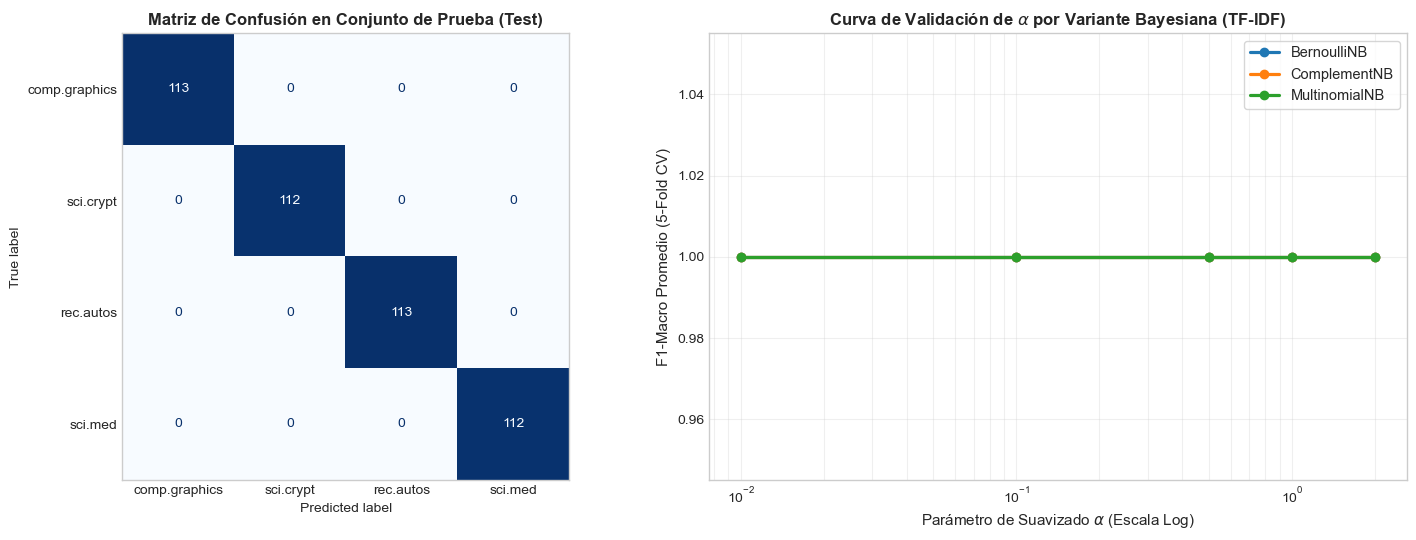

=== 1. TOP 8 TÉRMINOS CON MAYOR LOG-PROBABILIDAD (feature_log_prob_ = ln P(w | Y=c_k)) POR CLASE ===
• comp.graphics  : shader (lnP=-3.83, LLR=+2.12), matrix (lnP=-3.85, LLR=+2.09), framebuffer (lnP=-3.79, LLR=+2.08), mesh (lnP=-3.84, LLR=+2.02), display (lnP=-3.92, LLR=+2.01), texture (lnP=-3.84, LLR=+1.97), 3d (lnP=-3.92, LLR=+1.96), aliasing (lnP=-3.99, LLR=+1.95)
• sci.crypt      : cipher (lnP=-3.95, LLR=+2.16), algorithm (lnP=-3.79, LLR=+2.15), cryptography (lnP=-3.85, LLR=+2.13), rsa (lnP=-3.92, LLR=+2.09), bit (lnP=-3.83, LLR=+2.07), plaintext (lnP=-3.79, LLR=+2.05), certificate (lnP=-3.89, LLR=+2.05), aes (lnP=-3.84, LLR=+1.99)
• rec.autos      : mileage (lnP=-3.87, LLR=+2.32), radiator (lnP=-3.82, LLR=+2.21), brake (lnP=-3.84, LLR=+2.09), turbo (lnP=-4.00, LLR=+2.05), torque (lnP=-3.85, LLR=+1.97), exhaust (lnP=-3.91, LLR=+1.96), engine (lnP=-3.94, LLR=+1.95), oil (lnP=-3.88, LLR=+1.94)
• sci.med        : hospital (lnP=-3.82, LLR=+2.10), antibiotic (lnP=-3.85, LLR=+2.10), infe

In [11]:


# 📊 Paso 4 (Parte C): Matriz de Confusión, Curva de Validación de alpha e Interpretabilidad de feature_log_prob_
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel Izquierdo: Matriz de Confusión
cm = confusion_matrix(y_test_txt, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=categorias_nlp)
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Matriz de Confusión en Conjunto de Prueba (Test)', fontsize=12, fontweight='bold')
axes[0].grid(False)

# Panel Derecho: Sensibilidad a alpha según Clasificador (con TfidfVectorizer)
res_df = pd.DataFrame(grid_nlp.cv_results_)

# Filtro seguro de vectorizador TF-IDF y unigramas
mask_tfidf_uni = (
    res_df['param_vect'].astype(str).str.contains('TfidfVectorizer') &
    (res_df['param_vect__ngram_range'] == (1, 1))
)
df_plot = res_df[mask_tfidf_uni].copy()
df_plot['Modelo'] = df_plot['param_clf'].apply(lambda x: x.__class__.__name__)
df_plot['alpha'] = df_plot['param_clf__alpha'].astype(float)

# Graficar ordenando por alpha para evitar trazos cruzados
for modelo, grp in df_plot.groupby('Modelo'):
    grp_sorted = grp.sort_values('alpha')
    axes[1].plot(grp_sorted['alpha'], grp_sorted['mean_test_score'], marker='o', lw=2.3, label=modelo)

axes[1].set_xscale('log')
axes[1].set_xlabel(r'Parámetro de Suavizado $\alpha$ (Escala Log)', fontsize=11)
axes[1].set_ylabel('F1-Macro Promedio (5-Fold CV)', fontsize=11)
axes[1].set_title(r'Curva de Validación de $\alpha$ por Variante Bayesiana (TF-IDF)', fontsize=12, fontweight='bold')
axes[1].legend(frameon=True, facecolor='white', fontsize=10.5)
axes[1].grid(alpha=0.3, which='both')

plt.tight_layout()
plt.show()

# Extracción e Interpretación Analítica de feature_log_prob_ y Log-Likelihood Ratio (LLR)
vec_interpretable = TfidfVectorizer(ngram_range=(1, 1)).fit(X_train_txt)
mnb_interpretable = MultinomialNB(alpha=0.5).fit(vec_interpretable.transform(X_train_txt), y_train_txt)
feature_names_nlp = np.array(vec_interpretable.get_feature_names_out())

print("=== 1. TOP 8 TÉRMINOS CON MAYOR LOG-PROBABILIDAD (feature_log_prob_ = ln P(w | Y=c_k)) POR CLASE ===")
for c_idx, cat_name in enumerate(categorias_nlp):
    # Log-probabilidad de la clase objetivo
    log_prob_clase = mnb_interpretable.feature_log_prob_[c_idx]
    
    # Promedio de log-probabilidades en el resto de las clases
    otras_clases = np.delete(mnb_interpretable.feature_log_prob_, c_idx, axis=0)
    log_prob_resto = np.mean(otras_clases, axis=0)
    
    # Razón de log-verosimilitud (Log-Likelihood Ratio / Log-Odds discriminativo)
    llr_score = log_prob_clase - log_prob_resto
    
    top_indices = np.argsort(llr_score)[-8:][::-1]
    top_terms = [
        f"{feature_names_nlp[i]} (lnP={log_prob_clase[i]:.2f}, LLR=+{llr_score[i]:.2f})"
        for i in top_indices
    ]
    print(f"• {cat_name:<15}: {', '.join(top_terms)}")

---

## 6. Conclusiones y Reglas de Ingeniería para Modelos Discretos

1. **Elección de Variante en NLP:**
   * Si los documentos son cortos (tweets, asuntos de correo, SMS) y la no aparición de palabras clave aporta señal semántica, utiliza **`BernoulliNB`**.
   * Si el dataset presenta desbalance de clases importante, **`ComplementNB`** supera sistemáticamente a `MultinomialNB` en *Recall* y *F1-Macro* sobre las clases minoritarias.
   * Aunque `MultinomialNB` se deduce teóricamente sobre conteos enteros (`CountVectorizer`), en la práctica industrial funciona aún mejor con matrices de pesos fraccionarios **`TfidfVectorizer`** combinadas con un suavizado de Lidstone $\alpha \in [0.05, 0.5]$.
2. **Eficiencia con Matrices Dispersas (*Sparse Matrices*):**
   Jamás conviertas la salida de `CountVectorizer` o `TfidfVectorizer` a un arreglo denso con `.toarray()`. Los clasificadores `MultinomialNB`, `ComplementNB` y `BernoulliNB` operan nativamente sobre matrices comprimidas por filas (`scipy.sparse.csr_matrix`), permitiendo entrenar sobre vocabularios de $V > 100,000$ palabras usando apenas unos pocos megabytes de RAM.
3. **Variables Categóricas Tabulares:**
   Usa siempre `OrdinalEncoder` + `CategoricalNB(min_categories=...)` para variables categóricas nominales. Si un dataset tabular es **mixto** (combina columnas continuas y columnas categóricas), puedes sumar las log-verosimilitudes de un `GaussianNB` (sobre las continuas) y un `CategoricalNB` (sobre las categóricas) restando una vez el log-prior $\ln P(Y=c_k)$.

---
**Siguiente paso:** En el **Notebook 04 (`04_Calibracion_Streaming_y_Benchmark_Integral.ipynb`)** abordaremos la patología de probabilidades extremas y su calibración probabilística (Platt Scaling vs Regresión Isotónica), el entrenamiento fuera de núcleo (*Out-of-Core Streaming*) con `partial_fit` y un benchmark competitivo contra Regresión Logística, KNN, Árboles CART y Random Forest.